2025-11-27T01:00:26.529 2025-11-27T01:14:58.946


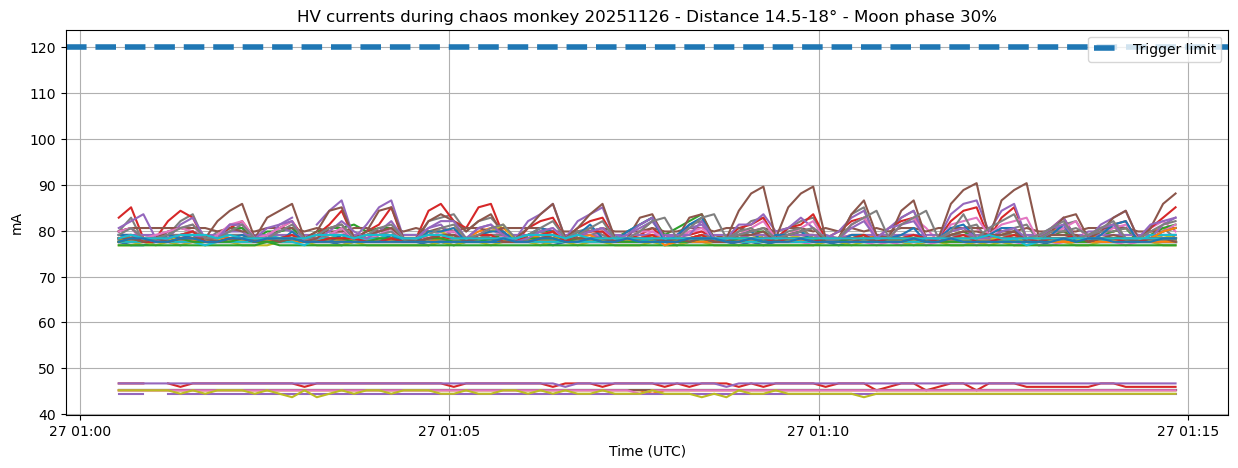

In [32]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import numpy as np
import gc
import lsst.daf.butler as DafButler
from lsst_efd_client import EfdClient 
import lsst.summit.utils.plotting as splot
from astropy.time import Time, TimeDelta

butler = DafButler.Butler('/repo/main', collections=["LSSTCam/runs/nightlyValidation","u/ataranto/lsst_outputs"], instrument='LSSTCam')
registry = butler.registry
client =  EfdClient('usdf_efd')
visit=[2025112600035]
for vis in visit:
    info=butler.get('raw.visitInfo', detector=94, exposure=vis)  #change exposure to visit for raw or post_isr
    st_time=str(info.date).split('"')[1]
    exposure=float(info.exposureTime)
    
    time_start = Time(st_time, scale="utc", format="isot")-TimeDelta(3, format='sec')

visit=[2025112600055]
for vis in visit:
    info=butler.get('raw.visitInfo', detector=94, exposure=vis)  #change exposure to visit for raw or post_isr
    st_time=str(info.date).split('"')[1]
    exposure=float(info.exposureTime)
    time_start1 = Time(st_time, scale="utc", format="isot")-TimeDelta(3, format='sec')
    time_end   = time_start1+TimeDelta(exposure+6, format='sec')
    print(time_start, time_end)

hv_bias=(await client.select_time_series(
    "lsst.sal.MTCamera.rebpower_Reb",
    fields=['hvbias_IbefSwch0', 'hvbias_IbefSwch1', 'hvbias_IbefSwch10', 'hvbias_IbefSwch11', 'hvbias_IbefSwch12', 'hvbias_IbefSwch13', 'hvbias_IbefSwch14', 'hvbias_IbefSwch15', 'hvbias_IbefSwch16', 'hvbias_IbefSwch17', 'hvbias_IbefSwch18', 'hvbias_IbefSwch19', 'hvbias_IbefSwch2', 'hvbias_IbefSwch20', 'hvbias_IbefSwch21', 'hvbias_IbefSwch22', 'hvbias_IbefSwch23', 'hvbias_IbefSwch24', 'hvbias_IbefSwch25', 'hvbias_IbefSwch26', 'hvbias_IbefSwch27', 'hvbias_IbefSwch28', 'hvbias_IbefSwch29', 'hvbias_IbefSwch3', 'hvbias_IbefSwch30', 'hvbias_IbefSwch31', 'hvbias_IbefSwch32', 'hvbias_IbefSwch33', 'hvbias_IbefSwch34', 'hvbias_IbefSwch35', 'hvbias_IbefSwch36', 'hvbias_IbefSwch37', 'hvbias_IbefSwch38', 'hvbias_IbefSwch39', 'hvbias_IbefSwch4', 'hvbias_IbefSwch40', 'hvbias_IbefSwch41', 'hvbias_IbefSwch42', 'hvbias_IbefSwch43', 'hvbias_IbefSwch44', 'hvbias_IbefSwch45', 'hvbias_IbefSwch46', 'hvbias_IbefSwch47', 'hvbias_IbefSwch48', 'hvbias_IbefSwch49', 'hvbias_IbefSwch5', 'hvbias_IbefSwch50', 'hvbias_IbefSwch51', 'hvbias_IbefSwch52', 'hvbias_IbefSwch53', 'hvbias_IbefSwch54', 'hvbias_IbefSwch55', 'hvbias_IbefSwch56', 'hvbias_IbefSwch57', 'hvbias_IbefSwch58', 'hvbias_IbefSwch59', 'hvbias_IbefSwch6', 'hvbias_IbefSwch60', 'hvbias_IbefSwch61', 'hvbias_IbefSwch62', 'hvbias_IbefSwch63', 'hvbias_IbefSwch64', 'hvbias_IbefSwch65', 'hvbias_IbefSwch66', 'hvbias_IbefSwch67', 'hvbias_IbefSwch68', 'hvbias_IbefSwch69', 'hvbias_IbefSwch7', 'hvbias_IbefSwch70', 'hvbias_IbefSwch8', 'hvbias_IbefSwch9'],
    start=time_start,
    end=time_end
))
# print(hv_bias.columns)
fig=plt.figure(figsize=(15,5))
plt.title('HV currents during chaos monkey 20251126 - Distance 14.5-18° - Moon phase 30%')
plt.plot(hv_bias['hvbias_IbefSwch8'].index,1000*hv_bias)
plt.axhline(120, ls='--', lw=4, label='Trigger limit')
plt.grid()
plt.xlabel('Time (UTC)')
plt.ylabel('mA')
plt.legend(loc='best')
plt.show()

In [12]:
print(hv_bias['hvbias_IbefSwch8'])

2025-11-27 01:14:29.673311+00:00    0.078312
2025-11-27 01:14:39.884252+00:00    0.078312
2025-11-27 01:14:50.029282+00:00    0.078312
Name: hvbias_IbefSwch8, dtype: float64


In [77]:
import numpy as np
from astropy.coordinates import Angle
import astropy.units as u
ro=21 *np.pi/180.0
theta=0  *np.pi/180.0
# Esempio: 12h 30m 15.5s
ra_string = '6h23m59.45s'
dec_string = '-52d41m45.0s'
dec= Angle(dec_string).rad
ra= Angle(ra_string).rad

In [78]:
sinp=np.sin(dec)*np.cos(ro)+np.cos(dec)*np.cos(theta)
point_dec=np.asin(sinp)*180.0/np.pi

In [79]:
del_ra= (np.atan2(np.sin(theta)*np.sin(ro)*np.cos(dec),np.cos(ro)-np.sin(dec)*np.sin(point_dec)))
print(del_ra*180.0/np.pi)

0.0


In [80]:
point_ra=(ra-del_ra)
point_ra = point_ra % (2 * np.pi)
print(point_ra*180/np.pi)

95.99770833333334


In [67]:
Angle(ra_string).degree

np.float64(95.99770833333332)

In [81]:
import math

# --- INPUT (Gradi) ---
ra_s_deg = 95.987      # Canopo RA in gradi (06h 23m 57s)
dec_s_deg = -52.695    # Canopo DEC in gradi
rho_deg = 25.0         # Distanza desiderata
theta_deg = 45.0       # Position Angle desiderato

# --- CONVERSIONE IN RADIANTI ---
alpha_s = math.radians(ra_s_deg)
delta_s = math.radians(dec_s_deg)
rho = math.radians(rho_deg)
theta = math.radians(theta_deg)

# --- FASE 2: TRIGONOMETRIA SFERICA ---
# 1. Calcolo Declinazione Punto P
sin_dec_p = (math.sin(delta_s) * math.cos(rho) + 
             math.cos(delta_s) * math.sin(rho) * math.cos(theta))
dec_p = math.asin(sin_dec_p)

# 2. Calcolo Differenza Ascensione Retta
y = math.sin(theta) * math.sin(rho) * math.cos(delta_s)
x = math.cos(rho) - math.sin(delta_s) * sin_dec_p
delta_alpha = math.atan2(y, x)

alpha_p = alpha_s - delta_alpha

# --- OUTPUT (Conversione per verifica) ---
print(f"DEC target: {math.degrees(dec_p):.4f} gradi")
print(f"RA target: {math.degrees(alpha_p) % 360:.4f} gradi")

DEC target: -32.6689 gradi
RA target: 75.1939 gradi


In [82]:
import math

def calcola_puntamento_altaz(phi_deg, ra_s_hms, dec_s_dms, lst_deg, t_frazione, rho_range, theta_range):
    """
    Calcola le coordinate Alt-Az del telescopio.
    t_frazione: da 0.0 (inizio) a 1.0 (fine)
    rho_range: (25.0, 19.0)
    theta_range: (45.0, 60.0) riferito allo Zenit
    """
    
    # 1. Interpolazione lineare dei parametri desiderati
    rho_deg = rho_range[0] + t_frazione * (rho_range[1] - rho_range[0])
    theta_deg = theta_range[0] + t_frazione * (theta_range[1] - theta_range[0])
    
    # Conversione in radianti
    phi = math.radians(phi_deg)
    rho = math.radians(rho_deg)
    theta = math.radians(theta_deg)
    
    # 2. Coordinate di Canopo (Conversione rapida HMS/DMS -> Deg)
    ra_s = math.radians((ra_s_hms[0] + ra_s_hms[1]/60 + ra_s_hms[2]/3600) * 15)
    sign = 1 if dec_s_dms[0] >= 0 else -1
    dec_s = math.radians(sign * (abs(dec_s_dms[0]) + dec_s_dms[1]/60 + dec_s_dms[2]/3600))
    lst = math.radians(lst_deg)
    
    # 3. Trovare Altezza e Azimut di Canopo (Posizione attuale)
    H_s = lst - ra_s
    sin_h_s = math.sin(phi) * math.sin(dec_s) + math.cos(phi) * math.cos(dec_s) * math.cos(H_s)
    h_s = math.asin(sin_h_s)
    
    az_s_num = math.sin(dec_s) - math.sin(phi) * sin_h_s
    az_s_den = math.cos(phi) * math.cos(h_s)
    az_s = math.acos(max(-1, min(1, az_s_num / az_s_den)))
    if math.sin(H_s) > 0: az_s = 2*math.pi - az_s

    # 4. Spostamento relativo rispetto allo Zenit (Coordinate del Telescopio)
    # Usiamo la distanza zenitale z = 90 - h
    z_s = math.pi/2 - h_s
    
    cos_z_p = math.cos(z_s) * math.cos(rho) + math.sin(z_s) * math.sin(rho) * math.cos(theta)
    z_p = math.acos(max(-1, min(1, cos_z_p)))
    h_p_deg = math.degrees(math.pi/2 - z_p)
    
    delta_az_num = math.sin(theta) * math.sin(rho)
    delta_az_den = math.sin(z_p) # Semplificazione valida per angoli non zenitali
    # Usiamo la legge dei seni/coseni combinata per l'Azimut
    sin_delta_az = (math.sin(theta) * math.sin(rho)) / math.sin(z_s)
    az_p_deg = math.degrees(az_s - math.asin(max(-1, min(1, sin_delta_az))))

    return h_p_deg, az_p_deg % 360

# --- ESEMPIO DI UTILIZZO ---
# Coordinate Canopo: 06h 23m 57s, -52° 41' 45"
# Supponiamo Latitudine -35° (Emisfero Sud) e LST attuale 100°
h_tel, az_tel = calcola_puntamento_altaz(
    phi_deg = -35.0, 
    ra_s_hms = (6, 23, 57), 
    dec_s_dms = (-52, 41, 45), 
    lst_deg = 100.0, 
    t_frazione = 0.5, # Siamo a metà osservazione
    rho_range = (25.0, 19.0), 
    theta_range = (45.0, 60.0)
)

print(f"Puntamento Telescopio a metà traiettoria:")
print(f"Altezza: {h_tel:.4f}° | Azimut: {az_tel:.4f}°")

Puntamento Telescopio a metà traiettoria:
Altezza: 72.2444° | Azimut: 112.9706°


In [3]:
import numpy as np
from astropy.coordinates import EarthLocation, SkyCoord, AltAz
from astropy.time import Time, TimeDelta
import astropy.units as u
import math

# Configurazione Rubin Observatory
loc = EarthLocation.of_site('Rubin')

def pianifica_osservazione_temporizzata(ora_inizio_iso, durata_totale_minuti, n_punti=10):
    # Coordinate Canopo (RA/DEC)
    ra_s_hms = (6, 23, 57)
    dec_s_dms = (-52, 41, 45)
    
    # Vincoli di traiettoria
    rho_start, rho_end = 25.0, 19.0
    theta_start, theta_end = 45.0, 60.0
    
    # Definizione del tempo di inizio
    t_start = Time(ora_inizio_iso)
    dt = durata_totale_minuti / (n_punti - 1)
    
    print(f"PIANO DI PUNTAMENTO DINAMICO - RUBIN OBSERVATORY")
    print(f"Inizio: {t_start.iso} UTC | Durata: {durata_totale_minuti} min")
    print("-" * 85)
    print(f"{'Ora (UTC)':<20} | {'Rho':<6} | {'Theta':<6} | {'Alt (h)':<10} | {'Az (Az)':<10}")
    print("-" * 85)

    for i in range(n_punti):
        # Frazione di completamento (da 0 a 1)
        f = i / (n_punti - 1)
        
        # 1. Calcolo del tempo specifico per questo punto
        t_attuale = t_start + TimeDelta(i * dt * 60, format='sec')
        
        # 2. Interpolazione dei vincoli relativi
        rho_val = rho_start + f * (rho_end - rho_start)
        theta_val = theta_start + f * (theta_end - theta_start)
        
        rho = math.radians(rho_val)
        theta = math.radians(theta_val)
        
        # 3. Posizione di Canopo in QUESTO preciso istante (tiene conto della rotazione terrestre)
        ra_str = f"{ra_s_hms[0]}h{ra_s_hms[1]}m{ra_s_hms[2]}s"
        dec_str = f"{dec_s_dms[0]}d{dec_s_dms[1]}m{dec_s_dms[2]}s"
        canopo = SkyCoord(ra_str, dec_str, frame='icrs')
        
        # Frame AltAz specifico per l'ora t_attuale
        altaz_frame = AltAz(obstime=t_attuale, location=loc)
        canopo_altaz = canopo.transform_to(altaz_frame)
        
        h_s = canopo_altaz.alt.rad
        az_s = canopo_altaz.az.rad
        z_s = math.pi/2 - h_s
        
        # 4. Calcolo del punto P spostato rispetto allo Zenit
        cos_z_p = math.cos(z_s) * math.cos(rho) + math.sin(z_s) * math.sin(rho) * math.cos(theta)
        z_p = math.acos(np.clip(cos_z_p, -1, 1))
        h_p_deg = math.degrees(math.pi/2 - z_p)
        
        # Calcolo differenza Azimutale
        num_az = math.cos(rho) - math.cos(z_s) * math.cos(z_p)
        den_az = math.sin(z_s) * math.sin(z_p)
        delta_az = math.acos(np.clip(num_az / (den_az if den_az != 0 else 1e-9), -1, 1))
        
        # Applichiamo lo spostamento ad Azimut di Canopo
        if math.sin(theta) > 0:
            az_p_deg = (math.degrees(az_s) + math.degrees(delta_az)) % 360
        else:
            az_p_deg = (math.degrees(az_s) - math.degrees(delta_az)) % 360

        print(f"{t_attuale.iso[11:19]:<20} | {rho_val:<6.1f} | {theta_val:<6.1f} | {h_p_deg:<10.4f} | {az_p_deg:<10.4f} ")

# ESEMPIO: Inizio stasera alle 22:00 UTC, durata 45 minuti
pianifica_osservazione_temporizzata('2026-01-12 22:00:00', 20)

PIANO DI PUNTAMENTO DINAMICO - RUBIN OBSERVATORY
Inizio: 2026-01-12 22:00:00.000 UTC | Durata: 20 min
-------------------------------------------------------------------------------------
Ora (UTC)            | Rho    | Theta  | Alt (h)    | Az (Az)   
-------------------------------------------------------------------------------------
22:00:00             | 25.0   | 45.0   | 42.4932    | 161.4024   
22:02:13             | 24.3   | 46.7   | 41.8538    | 161.1204   
22:04:26             | 23.7   | 48.3   | 41.2368    | 160.7965   
22:06:40             | 23.0   | 50.0   | 40.6436    | 160.4331   
22:08:53             | 22.3   | 51.7   | 40.0752    | 160.0323   
22:11:06             | 21.7   | 53.3   | 39.5324    | 159.5959   
22:13:20             | 21.0   | 55.0   | 39.0164    | 159.1259   
22:15:33             | 20.3   | 56.7   | 38.5279    | 158.6242   
22:17:46             | 19.7   | 58.3   | 38.0679    | 158.0924   
22:20:00             | 19.0   | 60.0   | 37.6370    | 157.5324   
